# Fine-Tuning DistilBERT for Sentiment Analysis and Attention Analysis

### Setup & Installation
First, we install the necessary Hugging Face libraries.

In [1]:
!pip install -q datasets transformers[torch] evaluate accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.7 MB/s eta 0:00:00


## Task 1: Data Loading & Inspection

In [2]:
from datasets import load_dataset
import pandas as pd

# Load the tweet_eval sentiment dataset using its full namespace
dataset = load_dataset('cardiffnlp/tweet_eval', 'sentiment')
print(dataset)

# Print class distribution in train split
train_df = pd.DataFrame(dataset['train'])
print("\nClass distribution:")
print(train_df['label'].value_counts())

# Save two example tweets per label (0: negative, 1: neutral, 2: positive)
examples = {}
for label in [0, 1, 2]:
    subset = train_df[train_df['label'] == label].head(2)
    examples[label] = subset['text'].tolist()

print("\nSaved examples:")
for lbl, texts in examples.items():
    print(f"Label {lbl}:")
    for t in texts:
        print(f" - {t}")

README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

sentiment/validation-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 45615
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 12284
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

Class distribution:
label
1    20673
2    17849
0     7093
Name: count, dtype: int64

Saved examples:
Label 0:
 - So disappointed in wwe summerslam! I want to see john cena wins his 16th title
 - That sucks if you have to take the SATs tomorrow
Label 1:
 - "Ben Smith / Smith (concussion) remains out of the lineup Thursday, Curtis #NHL #SJ"
 - Sorry bout the stream last night I crashed out but will be on tonight for sure. Then back to Minecraft in pc tomorrow night.
Label 2:
 - "QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin"
 - @user Alciato: Bee will invest 150 million in January, another 200 in the Summer and plans to bring Messi b

## Task 2: Tokenization Pipeline

In [3]:
from transformers import AutoTokenizer

model_checkpoint = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

def preprocess_function(examples):
    return tokenizer(examples['text'], truncation=True, padding='max_length', max_length=128)

tokenized_datasets = dataset.map(preprocess_function, batched=True)
tokenized_datasets.set_format("torch", columns=["input_ids", "attention_mask", "label"])

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/45615 [00:00<?, ? examples/s]

Map:   0%|          | 0/12284 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

## Task 3: Fine-Tuning Setup

In [4]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)
import numpy as np
import evaluate

# 1. Define your model checkpoint (e.g., DistilBERT)
model_checkpoint = "distilbert-base-uncased"

# 2. Load the tokenizer (needed for saving it later)
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

# --- Dataset Cleaning ---
# Rename 'label' to 'labels' if needed
if "label" in tokenized_datasets["train"].column_names and "labels" not in tokenized_datasets["train"].column_names:
    tokenized_datasets = tokenized_datasets.rename_column("label", "labels")

# Identify columns to remove (keep only what the model expects: input_ids, attention_mask, labels)
columns_to_remove = [col for col in tokenized_datasets["train"].column_names if col not in ["input_ids", "attention_mask", "labels"]]
tokenized_datasets = tokenized_datasets.remove_columns(columns_to_remove)
# ------------------------

# 3. Load the model for sequence classification
model = AutoModelForSequenceClassification.from_pretrained(
    model_checkpoint,
    num_labels=3,
)

accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")


def compute_metrics(eval_pred):
    logits, labels = eval_pred

    # Handle tuple outputs and ensure logits are a NumPy array
    if isinstance(logits, tuple):
        logits = logits[0]

    predictions = np.argmax(np.asarray(logits), axis=-1)

    acc = accuracy_metric.compute(
        predictions=predictions,
        references=labels,
    )["accuracy"]

    f1 = f1_metric.compute(
        predictions=predictions,
        references=labels,
        average="macro",
    )["f1"]

    return {"accuracy": acc, "macro_f1": f1}


training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",  # Modern Transformers parameter name
    save_strategy="epoch",
    learning_rate=5e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    compute_metrics=compute_metrics,
)

# Train the model
trainer.train()

# Save the best model and tokenizer together
model.save_pretrained("./best_model")
tokenizer.save_pretrained("./best_model")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.651167,0.642972,0.714000,0.692431
2,0.445371,0.633934,0.735500,0.709174
3,0.271453,0.786087,0.733500,0.716786


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./best_model/tokenizer_config.json', './best_model/tokenizer.json')

## Task 4: Evaluation & Calibration Plotting

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.271453,0.786087,3,0.733500,0.716786


Validation metrics: {'eval_loss': 0.786086916923523, 'eval_accuracy': 0.7335, 'eval_macro_f1': 0.7167859634812926}


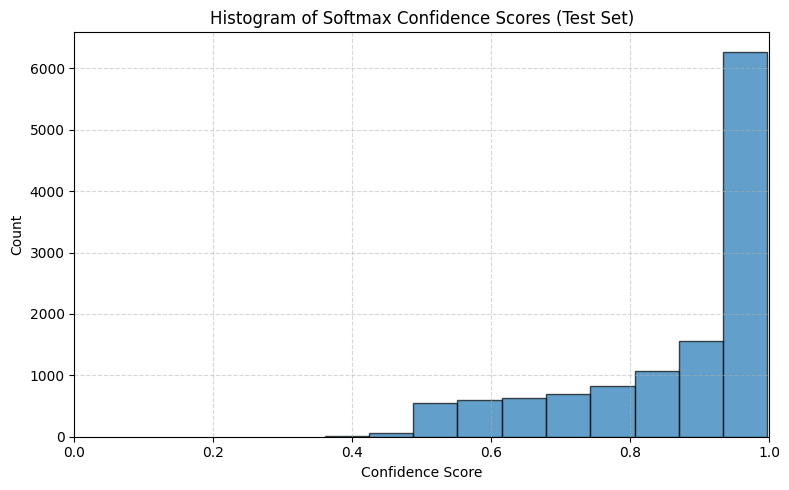

In [5]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# 1. Evaluate on the validation dataset
val_results = trainer.evaluate()
print("Validation metrics:", val_results)

# 2. Get predictions on the test dataset
predictions_output = trainer.predict(tokenized_datasets["test"])
logits = predictions_output.predictions

# Handle tuple outputs if the model returns multiple arrays
if isinstance(logits, tuple):
    logits = logits[0]

# Convert logits to a PyTorch tensor
logits = torch.as_tensor(logits, dtype=torch.float32)

# 3. Calculate softmax probabilities and confidence scores
probs = F.softmax(logits, dim=-1)
confidences, predicted_classes = torch.max(probs, dim=-1)

# Convert to NumPy safely (works even if tensors are on a GPU)
confidences = confidences.detach().cpu().numpy()
predicted_classes = predicted_classes.detach().cpu().numpy()

# 4. Plot confidence score histogram
plt.figure(figsize=(8, 5))
plt.hist(confidences, bins=10, edgecolor="black", alpha=0.7)
plt.title("Histogram of Softmax Confidence Scores (Test Set)")
plt.xlabel("Confidence Score")
plt.ylabel("Count")
plt.xlim(0, 1)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Task 5: Attention Inspection & Production-Style Function

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

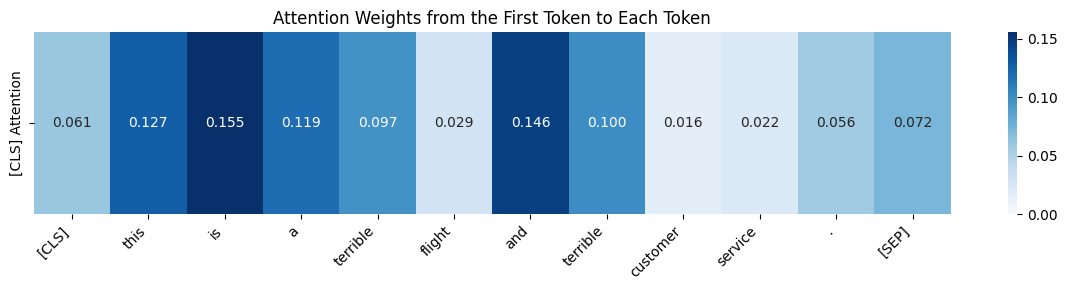

In [6]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoModelForSequenceClassification

# Use a saved negative text example
sample_text = "This is a terrible flight and terrible customer service."

# Load the trained classification model with attention outputs enabled
model_with_attention = AutoModelForSequenceClassification.from_pretrained(
    "./best_model",
    output_attentions=True,
    attn_implementation="eager",
)
model_with_attention.eval()

# Tokenize the input
inputs = tokenizer(sample_text, return_tensors="pt")

# Ensure inputs and model are on the same device
device = next(model_with_attention.parameters()).device
inputs = {key: value.to(device) for key, value in inputs.items()}

# Run inference without calculating gradients
with torch.no_grad():
    outputs = model_with_attention(**inputs)

# Check whether attention weights were returned
if outputs.attentions is None:
    raise RuntimeError(
        "Attention weights were not returned. Check model compatibility "
        "and ensure output_attentions=True."
    )

# Get attention from the last transformer layer
# Shape: (num_heads, sequence_length, sequence_length)
last_layer_attention = outputs.attentions[-1][0]

# Average attention weights across all heads
avg_attention = (
    last_layer_attention.mean(dim=0).detach().cpu().numpy()
)

# Get tokens and CLS attention weights
input_ids = inputs["input_ids"][0].detach().cpu().tolist()
tokens = tokenizer.convert_ids_to_tokens(input_ids)
cls_attention = avg_attention[0]

# Plot CLS attention
plt.figure(figsize=(max(12, len(tokens) * 0.8), 3))
sns.heatmap(
    cls_attention[np.newaxis, :],
    xticklabels=tokens,
    yticklabels=["[CLS] Attention"],
    annot=True,
    fmt=".3f",
    cmap="Blues",
    vmin=0,
)
plt.title("Attention Weights from the First Token to Each Token")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [7]:
import torch
import torch.nn.functional as F

# Ensure both models are in evaluation mode
model.eval()
model_with_attention.eval()

labels_map = {
    0: "negative",
    1: "neutral",
    2: "positive",
}


def analyze_text(text):
    # Tokenize input
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128,
    )

    # Move inputs to the device used by the prediction model
    device = next(model.parameters()).device
    inputs = {key: value.to(device) for key, value in inputs.items()}

    # Run inference
    with torch.no_grad():
        outputs = model(**inputs)

        # Ensure attention model is on the same device
        attention_device = next(model_with_attention.parameters()).device
        attention_inputs = {
            key: value.to(attention_device)
            for key, value in inputs.items()
        }
        attention_outputs = model_with_attention(**attention_inputs)

    # Class prediction
    probs = F.softmax(outputs.logits, dim=-1)[0]
    confidence, label_idx = torch.max(probs, dim=0)

    # Extract attention from the final layer, averaged across heads
    if attention_outputs.attentions is None:
        raise RuntimeError(
            "Attention weights are unavailable. Load the model with "
            "output_attentions=True and a compatible attention implementation."
        )

    last_layer_att = (
        attention_outputs.attentions[-1][0]
        .mean(dim=0)
        .detach()
        .cpu()
        .numpy()
    )

    # Attention from the first token to all tokens
    cls_att = last_layer_att[0]

    # Convert token IDs to readable tokens
    input_ids = inputs["input_ids"][0].detach().cpu().tolist()
    tokens = tokenizer.convert_ids_to_tokens(input_ids)

    highlighted_tokens = [
        (token, float(score))
        for token, score in zip(tokens, cls_att.tolist())
    ]

    return {
        "label": labels_map.get(label_idx.item(), "unknown"),
        "confidence": confidence.item(),
        "highlighted_tokens": highlighted_tokens,
    }


# Example
result = analyze_text(
    "The service was outstanding and extremely fast!"
)
print(result)

{'label': 'positive', 'confidence': 0.9962588548660278, 'highlighted_tokens': [('[CLS]', 0.038053303956985474), ('the', 0.0589604526758194), ('service', 0.07694073766469955), ('was', 0.10240622609853745), ('outstanding', 0.08004883676767349), ('and', 0.07101728767156601), ('extremely', 0.07067005336284637), ('fast', 0.03694887086749077), ('!', 0.27015841007232666), ('[SEP]', 0.1947958618402481)]}
